# Análisis Exploratorio de Datos

En este notebook se exploran los distintos archivos csv para...

In [104]:
import numpy as np
import pandas as pd 
import math
import matplotlib.pyplot as plt # Basic plots
import seaborn as sns   
import json
import os
import shutil

import eda

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## The Movies Dataset

Esta base contiene 7 archivos csv: credits, keywords, links_small, movies_metadata y ratings_small.

Dentro de ellos, hay dos que contienen información reducida (los que contienen la palabra "small"). Como un primer análisis nos enfocamos a explorar credits, keywords, movies_metadata, y los que tienen la palabra "small".

https://www.kaggle.com/rounakbanik/the-movies-dataset?select=movies_metadata.csv

In [105]:
### Cargamos los csv originales
credits = pd.read_csv('dataset-1/credits_original.csv')
keywords = pd.read_csv('dataset-1/keywords_original.csv')
links_small = pd.read_csv('dataset-1/links_small.csv')
links = pd.read_csv('dataset-1/links.csv')
ratings = pd.read_csv('dataset-1/ratings.csv')
ratings_small = pd.read_csv('dataset-1/ratings_small.csv')
movies_metadata = pd.read_csv('dataset-1/movies_metadata_original.csv')


### Les quitamos 3 renglones que traen informacion erronea
credits = eda.remove_rows(credits, 'dataset-1/credits.csv')
keywords = eda.remove_rows(keywords, 'dataset-1/keywords.csv')
movies_metadata = eda.remove_rows(movies_metadata, 'dataset-1/movies_metadata.csv')

## Algunas modificaciones
movies_metadata['id'] = movies_metadata['id'].apply(lambda x : int(x)) 
movies_metadata['popularity'] = movies_metadata['popularity'].apply(lambda x : float(x))


### Cargamos (o creamos) DataFrames derivados de los originales para facilitar el manejo de los datos
credits_cast = eda.concat_df(credits, 'cast', 'dataset-1/credits_cast.csv')
credits_crew = eda.concat_df(credits, 'crew', 'dataset-1/credits_crew.csv')
movies_metadata_production_countries = eda.concat_df(movies_metadata, 'production_countries', 'dataset-1/movies_metadata_production_countries.csv')
movies_metadata_production_companies = eda.concat_df(movies_metadata, 'production_companies', 'dataset-1/movies_metadata_production_companies.csv')
movies_metadata_spoken_languages = eda.concat_df(movies_metadata, 'spoken_languages', 'dataset-1/movies_metadata_spoken_languages.csv')
movies_metadata_genres = eda.concat_df(movies_metadata, 'genres', 'dataset-1/movies_metadata_genres.csv')
keywords_keywords = eda.concat_df(keywords, 'keywords', 'dataset-1/keywords_keywords.csv')

## Algunas modificaciones
credits_cast['id'] = credits_cast['id'].apply(lambda x : int(x))
credits_cast['order_metric'] = credits_cast['order_metric'].apply(lambda x : float(x))
credits_cast['order_metric2'] = credits_cast['order_metric2'].apply(lambda x : float(x))

c:\users\mike\appdata\local\programs\python\python39\lib\site-packages\IPython\core\interactiveshell.py:3165: DtypeWarning: Columns (10) have mixed types.Specify dtype option on import or set low_memory=False.
  has_raised = await self.run_ast_nodes(code_ast.body, cell_name,


### credits_csv

Inspeccionamos carácterísticas básicas como las dimensiones y las variables

In [106]:
print('Dimensiones del csv: {}'.format(credits.shape))
credits.info()

Dimensiones del csv: (45473, 3)
<class 'pandas.core.frame.DataFrame'>
Int64Index: 45473 entries, 0 to 45475
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   cast    45473 non-null  object
 1   crew    45473 non-null  object
 2   id      45473 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 1.4+ MB


Una primera vista a este csv no nos da mucha indicación del contenido. Vemos que tanto la columna <strong>cast</strong> como <strong>crew</strong> son listas de diccionarios, por lo que será necesario hacer algunas manipulaciones.

In [107]:
credits.head(3)

,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602


Al hacer ciertas manipulaciones, vemos que en la columna <strong>cast</strong> se encuentran los nombres de los personajes, el actor que los interpretó, género, y una variable de orden (que tal vez se pueda ocupar posteriormente para determinar que tan relevante fue el actor en la película).

In [108]:
eval(credits['cast'][0])[:2]

[{'cast_id': 14,
  'character': 'Woody (voice)',
  'credit_id': '52fe4284c3a36847f8024f95',
  'gender': 2,
  'id': 31,
  'name': 'Tom Hanks',
  'order': 0,
  'profile_path': '/pQFoyx7rp09CJTAb932F2g8Nlho.jpg'},
 {'cast_id': 15,
  'character': 'Buzz Lightyear (voice)',
  'credit_id': '52fe4284c3a36847f8024f99',
  'gender': 2,
  'id': 12898,
  'name': 'Tim Allen',
  'order': 1,
  'profile_path': '/uX2xVf6pMmPepxnvFWyBtjexzgY.jpg'}]

De igual manera, la columna <strong>crew</strong> contiene información de toda persona involucrada en la creación de la película que NO es actor/actriz, como lo son productores, escritores, arte, etc.

In [109]:
eval(credits['crew'][0])[:2]

[{'credit_id': '52fe4284c3a36847f8024f49',
  'department': 'Directing',
  'gender': 2,
  'id': 7879,
  'job': 'Director',
  'name': 'John Lasseter',
  'profile_path': '/7EdqiNbr4FRjIhKHyPPdFfEEEFG.jpg'},
 {'credit_id': '52fe4284c3a36847f8024f4f',
  'department': 'Writing',
  'gender': 2,
  'id': 12891,
  'job': 'Screenplay',
  'name': 'Joss Whedon',
  'profile_path': '/dTiVsuaTVTeGmvkhcyJvKp2A5kr.jpg'}]

Para facilitar el trabajo de los valores en este DataFrame, convendría crear nuevas tablas para cada columna. 

Con previo conocimiento que existen otras columans dentro de otros csv que requeriran este tratamiento (como <strong>crew</strong> en este mismo), creamos funciones que facilitan el manejo de tales variables. Así mismo, nos convendría guardar en nuevos csv a los valores tratados, tal que no sea necesario volver a correr esto cada vez que se corra el notebook.

Las funciones que hacen esto son **turn_col_to_df** y **concat_df** dentro del script **eda.py**

Algunas observaciones sobre <strong>cast</strong>:

    1. Hay peliculas cuyos personajes no vienen incluidos, pero si otro tipo de informacion. Existe la probabilidad de que o bien sea un error de la base, o que se traten de peliculas donde cada actor se interpreta a si mismo como personaje. Sin mayor informacion al respecto, quiza igualmente podriamos eliminar estos valores si es que abarcan una cantidad menor en la base.
    2. Hay peliculas donde si existe crew pero no cast. Podria tratarse de errores o tal vez de documentales o peliculas donde no hay actores. Nuevamente podriamos eliminarlos si representan una cantidad poco significativa.

Una vez transformados los json, podemos visualizar los dataframes para **cast** y **crew**. Incluimos solo las variables que hemos visto que podemos ocupar:

In [154]:
credits_cast.head().drop(['credit_id', 'profile_path', 'order_metric', 'order_metric2', 'id_credits'], 1)

,cast_id,character,gender,id,name,order,parent_id
0,14.0,Woody (voice),2.0,31,Tom Hanks,0.0,0
1,15.0,Buzz Lightyear (voice),2.0,12898,Tim Allen,1.0,0
2,16.0,Mr. Potato Head (voice),2.0,7167,Don Rickles,2.0,0
3,17.0,Slinky Dog (voice),2.0,12899,Jim Varney,3.0,0
4,18.0,Rex (voice),2.0,12900,Wallace Shawn,4.0,0


In [111]:
credits_crew.head().drop(['credit_id', 'profile_path'], 1)

,department,gender,id,job,name,parent_id
0,Directing,2.0,7879.0,Director,John Lasseter,0
1,Writing,2.0,12891.0,Screenplay,Joss Whedon,0
2,Writing,2.0,7.0,Screenplay,Andrew Stanton,0
3,Writing,2.0,12892.0,Screenplay,Joel Cohen,0
4,Writing,0.0,12893.0,Screenplay,Alec Sokolow,0


Exploramos las variables para ver a que se refieren. Por ejemplo, dentro de <strong>cast</strong> vemos que <strong>id</strong> se refiere al nombre del actor:

In [112]:
credits_cast[credits_cast.id == 100].head(3)

,cast_id,character,credit_id,gender,id,name,order,profile_path,parent_id,order_metric,order_metric2,id_credits
65390,2.0,Billy,52fe475e9251416c75096ce9,2.0,100,Scott Speedman,1.0,/hxDr3YjCYaHPEFbEfC0eXjMps0u.jpg,3777,0.833333,0.833333,18074
100714,12.0,Bobby Keough,52fe43e2c3a36847f8076041,2.0,100,Scott Speedman,1.0,/hxDr3YjCYaHPEFbEfC0eXjMps0u.jpg,6047,0.941176,0.941176,4911
109258,22.0,Michael Corvin,52fe4231c3a36847f800b0cd,2.0,100,Scott Speedman,1.0,/hxDr3YjCYaHPEFbEfC0eXjMps0u.jpg,6605,0.968750,0.968750,277


No obstante, observamos en el siguiente histograma como de forma no natural hay una acumulacion de valores muy grandes de **id**. Tal vez no es de mayor preocupacion, pero seria bueno tenerlo en cuenta.

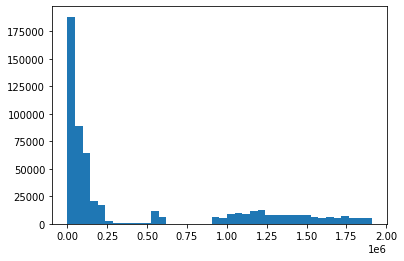

In [113]:
fig, ax = plt.subplots()
ax.hist(credits_cast.sort_values(by = 'id', ascending = False)['id'], bins=40);plt.show()

Para determinar que actores son mejores, requeriremos definir alguna o varias metricas. Una de ellas puede ser la cuenta de en que tantas peliculas han aparecido (y tal vez despues debamos normalizarlo). Vemos dentro del top 10 de apariciones varios nombres conocidos como es de esperarse.

In [114]:
actor_counts = credits_cast['name'].value_counts()
actor_counts.head(10)

Bess Flowers         241
Christopher Lee      148
John Wayne           125
Samuel L. Jackson    123
Gérard Depardieu     110
Michael Caine        110
John Carradine       109
Donald Sutherland    109
Jackie Chan          108
Frank Welker         107
Name: name, dtype: int64

#### Issue #1

Dados los dos proyectos que se tienen, i.e. poder determinar el exito de una nueva pelicula contemplando diferentes combinaciones de actores, director, etc y hacer un algun algoritmo de recomendacion de peliculas, notamos que para el primero no podemos incluir actores que hayan fallecido. Derivado de esto, tenemos que idear una forma de filtrar a estos. Una posible forma, aunque extremadamente tardada, seria buscar y asignar uno por uno un boolean que lo determine. Otra forma, mas rapída aunque posiblemente complicada de implementar, seria ocupar BeautifulSoup o algun modulo que busque los nombres en alguna pagina como IMDb o Wikipedia, y encontrar la forma en que dentro de la pagina se pueda determinar si ha fallecido o no. Un posible problema en este segundo caso seria el que haya nombres repetidos, para lo cual se podria solucionar buscando ademas alguna pelicula asociada al actor.

#### Solucion

En la base de IMDb hay una columna de fecha de fallecimiento. Podemos ocupar esa para todos los actores que coincidan en ambas bases.

### Metrica de orden de actores

Asiumiendo que la variable **order** dentro de **credits_cast** si hace referencia al orden de importancia del actor en la pelicula, nos interesaria poder ocuparla para rankear a los actores. Como el 0 parece ser el valor mas importante y de ahi va subiendo, nos interesaria establecer una metrica inversa para que el 0 sea mapeado a un valor mas grande que el 1,2,etc.

Proponemos entonces lo siguiente:

Fijando el **id** de la pelicula $p$ (i.e. **parent_id**), definimos la metrica de orden como:

$$ M_{k,p} = 1 - O_{k,p}/(N_p)$$

donde $O_{k,p}$ es el valor de orden del actor k en la pelicula $p$, y $N_p$ es la cantidad de actores en tal pelicula. Asi, cuando $O_{k,p} = 0$, entonces $ M_{k,p} = 1$, y va decreciendo conforme aumente el valor de $O_{k,p}$.

In [115]:
if 'order_metric' not in credits_cast.columns:
    credits_cast['order_metric'] = None

    for k in credits_cast['parent_id'].unique():
        aux = credits_cast[credits_cast['parent_id'] == k]
        credits_cast.loc[aux.index, 'order_metric'] = np.array(1 - aux['order']/len(aux))
    
    credits_cast.to_csv('dataset-1/credits_cast.csv')

credits_cast['order_metric'] = credits_cast['order_metric'].apply(lambda x : float(x))

In [116]:
if 'order_metric2' not in credits_cast.columns:
    credits_cast['order_metric2'] = None

    for k in credits_cast['parent_id'].unique():
        aux = credits_cast[credits_cast['parent_id'] == k]
        credits_cast.loc[aux.index, 'order_metric2'] = np.array(1 - np.array(range(len(aux)))/len(aux))

    credits_cast.to_csv('dataset-1/credits_cast.csv')
    
credits_cast['order_metric2'] = credits_cast['order_metric2'].apply(lambda x : float(x))

#### Un comentario sobre la metrica de orden de actores

Aun si dos actores tienen por ejemplo un valor de 1 en la metrica, no implica que los dos sean en general "igual de buenos". Por ejemplo, no podemos directamente comparar a Tom Hanks en Toy Story contra el actor principal en alguna pelicula de bajo renombre.

Más adelante se vio que como **order** no siempre empieza en 0, habia valores erroneamente calculados. Por ello, creamos **order_metric2** que resuelve esto.

In [117]:
credits_cast['order_metric'][credits_cast['order_metric'] < 0].sort_values()

504899   -23.000000
522140    -9.000000
405381    -7.333333
547341    -5.142857
547340    -5.000000
            ...    
14767     -0.006623
215936    -0.005952
202476    -0.005464
180437    -0.005405
502731    -0.004808
Name: order_metric, Length: 3665, dtype: float64

In [118]:
credits_cast['order_metric2'][credits_cast['order_metric2'] < 0].sort_values()

Series([], Name: order_metric2, dtype: float64)

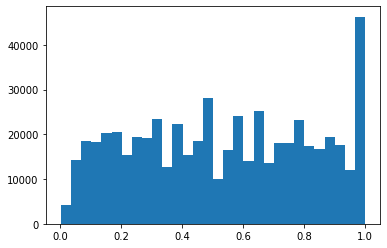

In [119]:
fig, ax = plt.subplots()
ax.hist(credits_cast['order_metric2'], bins = 30); plt.show()

De esta forma, comparando con los resultados anteriores, vemos que por ejemplo aunque Bess Flowers participo en 241 peliculas, en general era como extra, por lo que una mejor forma de representar la importancia es a traves de la orden de metrica propuesta:

In [120]:
credits_cast.groupby('name').sum()['order_metric2'].sort_values(ascending = False).head(10)

name
John Wayne            110.503753
Christopher Lee       110.045172
Jackie Chan           100.674952
Michael Caine          98.446688
Samuel L. Jackson      98.395827
Robert De Niro         94.551622
Gérard Depardieu       94.200447
Donald Sutherland      84.999187
Christopher Walken     79.147906
Harvey Keitel          77.183234
Name: order_metric2, dtype: float64

Complementando la metrica generada, nos gustaria combinarla con los ratings. Una primera idea seria ocupar el promedio de **rating** fijando **movieId**:

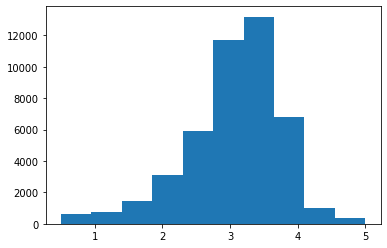

In [121]:
fig, ax = plt.subplots()
ax.hist(ratings.groupby('movieId').mean().rating); plt.show()

#### Issue

No obstante, notamos que hay una cantidad significativa de peliculas para los cuales muy pocos usuarios votaron.

Por ejemplo, un 39.87% de las peliculas tienen menos de 5 votos. 

#### Solucion

Algunas posibles soluciones serian:

    1. Descartar las peliculas con menos de 3 (4, 5, etc. habra que ver el mejor corte) votos
    2. Asociarle a las que tengan menos de X votos el promedio de ratings
    3. Ignorarlo y trabajar asumiendo que aun 1 solo voto fue suficiente

In [122]:
len(aux[aux < 5])/len(aux)

0.39726515522693867

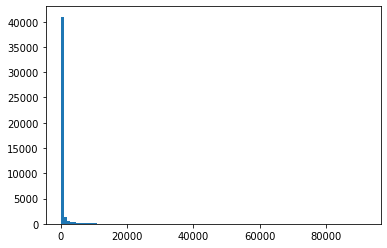

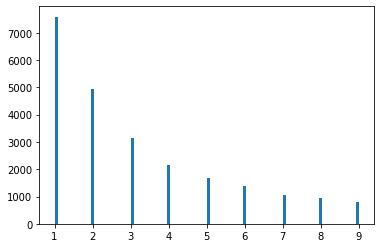

In [123]:
aux = ratings.groupby('movieId').count().rating

aux[aux < 5]

fig, ax = plt.subplots()
ax.hist(aux, bins = 100); plt.show()

fig, ax = plt.subplots()
ax.hist(aux[aux < 10], bins = 100); plt.show()

### Metrica score actor

Hay que ser cuidadosos con la definicion de la metrica  que resuma que tan bueno es un actor. Como ya hemos mencionado, no podemos simplemente tomar la cantidad de peliculas en las que ha salido, ni la metrica de orden que definimos, ni un promedio de ratings de las peliculas en las que ha salido. Al menos tendriamos que considerar esas 3 cantidades en conjunto y asociar una regla de correspondencia que sea coherente.

Previo a definir la metrica, mencionamos algunas cosas que nos gustaria evitar. Para este ejemplo, asumamos que $A_1$ es Tom Hanks, quien ha salido en multiples peliculas (72 en la base) que podrian ser consideradas buenas, $A_2$ es Marc Price, un actor elegido a proposito dado que tiene un orden de 0 (actor mas importante) y solo ha aparecido en una pelicula, y $A_3$ es Gerard Butler, que ha salido en 36 peliculas de acuerdo a la base (la mitad que Tom Hanks).

1. Suponiendo que la pelicula de $A_2$ tuvo rating de 5 (perfecto) y que el promedio de las 72 peliculas en las que ha salido $A_1$ sea menor a 5 (muy probable), no nos gustaria decir que $score(A_1) <= score(A_2)$, ya que, si bien pudiera existir la posibilidad que $A_2$ en verdad sea mejor que $A_1$, existen muy pocos registros (1 en este caso) para respaldarlo.

2. Suponiendo que el promedio de $A_1$ y $A_3$ en ratings es el mismo (digamos 4.2), y dado que la cantidad de peliculas en las que ha salido $A_1$ es el doble que $A_3$, no nos gustaria alguna relacion del estilo $score(A_1) = 2*score(A_3)$, sino tal vez aplicar logaritmos para que si se preserve $score(A_1) > score(A_3)$ pero no por tanto.

#### Sobre ocupar links

Algo muy importante previo a ocupar directamente **movieId** en **ratings** como si fuera el **id** en **credits** o en **movies_metadata**, es que este no es el mismo. Mas bien, hay que ocupar el csv de **links** para conectarlos, en la cual **movieId** coincide con **movieId** en **ratings**, y **tmdbid** coincide con **id** en **credits** y **movies_metadata**.

Las siguientes celdas nos ayudan justamente a unir todo tomando esto en cuenta.

In [125]:
if 'id_credits' not in credits_cast.columns:
    credits_cast = credits_cast.join(credits, rsuffix = '_credits', on = 'parent_id', how = 'inner').drop(['crew', 'cast'], 1)
    credits_cast.to_csv('dataset-1/credits_cast.csv')
    
credits_cast['id_credits'] = credits_cast['id_credits'].apply(lambda x : int(x))

In [130]:
if 'tmdbId' not in ratings.columns:
    ratings = ratings.join(links.set_index('movieId'), on = 'movieId')
    ratings = ratings.dropna() #Son muy pocos los NA
    ratings.drop('Unnamed: 0', 1, inplace = True)
    ratings.to_csv('dataset-1/ratings.csv')

ratings['tmdbId'] = ratings['tmdbId'].apply(lambda x: int(x))

Calculamos la media de ratings por id

In [133]:
mean_ratings = ratings.groupby('tmdbId').mean().rating
mean_ratings

tmdbId
2         3.673664
3         3.770115
5         3.409031
6         2.924862
11        4.132299
            ...   
465044    0.500000
467731    3.500000
468343    3.250000
468707    4.000000
469172    3.833333
Name: rating, Length: 44872, dtype: float64

Y ahora sí calculamos el score:

In [143]:
aux = credits_cast.join(mean_ratings, how = 'inner', on = 'id_credits')#[['name', 'id', 'order_metric', 'rating']]
aux['actor_score'] = aux['order_metric2']*aux['rating']
aux = aux.groupby('id').sum()['actor_score'].apply(lambda x: np.log(x))
# aux = aux.groupby('id').mean()['actor_score']

score_actor = credits_cast[['name', 'id']].drop_duplicates().join(aux, how = 'inner', on = 'id')

sfsdf

In [151]:
score_actor.sort_values(by = 'actor_score', ascending = False)[['name', 'actor_score']].set_index('name').head(10)

,actor_score
name,
John Wayne,5.802742
Christopher Lee,5.761341
Michael Caine,5.750418
Robert De Niro,5.742976
Samuel L. Jackson,5.740141
Jackie Chan,5.717167
Gérard Depardieu,5.685686
Donald Sutherland,5.613232
Morgan Freeman,5.497684


Veamos si algunas de las condiciones que queriamos se cumplen

In [152]:
print(score_actor[score_actor['name'] == 'Tom Hanks'])
print(score_actor[score_actor['name'] == 'Mark Price'])

        name  id  actor_score
0  Tom Hanks  31     5.313627
Empty DataFrame
Columns: [name, id, actor_score]
Index: []


In [153]:
print(score_actor[score_actor['name'] == 'Tom Hanks'])
print(score_actor[score_actor['name'] == 'Gerard Butler'])

        name  id  actor_score
0  Tom Hanks  31     5.313627
                name     id  actor_score
27577  Gerard Butler  17276     4.653264


#### Un comentario sobre la variable popularity

Los valores de **popularity** en principio nos podrian servir para rankear tanto peliculas como actores. El tema es que la escala no es clara, ya que el valor minimo (0) esta muy lejos del maximo, y en general la mayoria de los valores son muy bajos.

count    45460.000000
mean         2.921478
std          6.005414
min          0.000000
25%          0.385948
50%          1.127685
75%          3.678902
max        547.488298
Name: popularity, dtype: float64


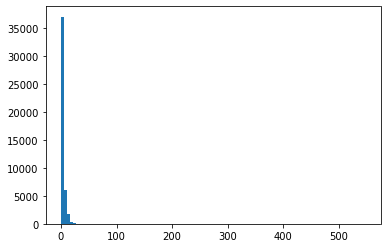

In [ ]:
movies_metadata['popularity'].sort_values()
print(movies_metadata['popularity'].describe())
fig, ax = plt.subplots()
ax.hist(movies_metadata['popularity'], bins = 100);plt.show()

Aplicando logaritmos y sustituyendo los $-\infty$ por el minimo, vemos la siguiente distribucion, que condieramos aporta mas valor si quisieramos ocupar esta variable en el futuro.

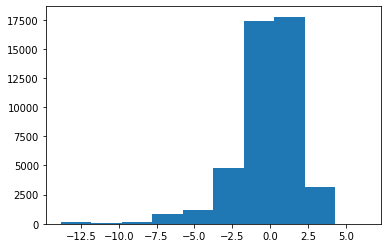

In [ ]:
aux = movies_metadata['popularity'].sort_values().dropna().apply(lambda x : np.log(x))#.replace(-np.inf, 1)
aux = aux.replace(-np.inf, aux[aux != -np.inf].min())

fig, ax = plt.subplots()
ax.hist(aux);plt.show()

## Tasas de Cambio

Los presupuestos en general están en diferentes monedas. Para hacerlos comparables, necesitamos las tasas de tipo de cambio.

In [ ]:
fx_usd_mxn = pd.read_csv('fx-rates/MXN=X.csv')
fx_usd_mxn.set_index('Date', inplace = True)
fx_usd_mxn = fx_usd_mxn['Adj Close']
fx_usd_mxn.index = pd.to_datetime(fx_usd_mxn.index, format='%Y-%m-%d')
fx_usd_mxn = fx_usd_mxn.resample('Y').mean()
fx_usd_mxn.index = np.array(fx_usd_mxn.reset_index()['Date'].apply(lambda x : x.year))
fx_usd_mxn.name = 'USD/MXN'

In [ ]:
fx_usd_mxn

2005    10.836333
2006    10.882758
2007    10.922167
2008    11.212758
2009    13.574783
2010    12.659144
2011    12.473842
2012    13.137146
2013    12.837953
2014    13.367064
2015    15.977279
2016    18.714560
2017    18.870592
2018    19.163766
2019    19.304882
Name: USD/MXN, dtype: float64

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=ad7fd148-33f5-4535-84e5-f963edc6e722' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>